# Book for test

### Libs

In [1]:
import json, numpy as np, pandas as pd, warnings, matplotlib.pyplot as plt

from sklearn.feature_selection import SelectFromModel, VarianceThreshold
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import KFold#, cross_val_score
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from src.helpers.convert_class import convert_to_natural, natural_to_original
from src.helpers import approaches_class as apc
#from src.helpers.convert_class import convert_to_high_low
from src.utility.generate_datasets import create_df
from src.utility.create_model_files import model_files
from src.helpers.output_index import (
    patrimony,
    drawdown,
    percent_return_p,
    daily_return,
    sharpe,
    trade_hit,
    gain_loss_ratio,
    roi as ROI,
)

np.random.seed(0)
warnings.filterwarnings("ignore")

### Functions

In [2]:
def product(args, repeat=1):
    """
    product('ABCD', 'xy') --> Ax Ay Bx By Cx Cy Dx Dy
    product(range(2), repeat=3) --> 000 001 010 011 100 101 110 111
    """
    pools = [tuple(pool) for pool in args] * repeat
    result = [[]]
    for pool in pools:
        result = [x + [y] for x in result for y in pool]
    for prod in result:
        yield tuple(prod)

### Parameters

In [3]:
ticker = "ABEV3.SA"
model_version = 1.0
model_plan = "basic"

In [4]:
# Parameters
ticker = "EMBR3.SA"
model_plan = "basic"
model_version = 2.0


In [5]:
years_train = 6
val_days_partition = 250
years_test = 3
if model_version==3.0:
    scaling=True
else:
    scaling = False
smooth_days = 1
smooth_perc = [0.75/100, 1/100, 1.25/100]
selic = 10.75 # 16/10/2024
p = 0.8
generate_last_model = False

In [6]:
now = pd.Timestamp(year=2024, month=10, day=10) #pd.Timestamp.now()

#start = (now - pd.Timedelta(days=(years_train+years_test)*365)).strftime("%Y-%m-%d")
#end = (now - pd.Timedelta(days=years_test*365)).strftime("%Y-%m-%d")
start = pd.Timestamp(year=2010, month=1, day=3).strftime("%Y-%m-%d")
end = pd.Timestamp(year=2019, month=12, day=30).strftime("%Y-%m-%d")

start_valid = pd.Timestamp(year=2019, month=12, day=10).strftime("%Y-%m-%d")
end_valid = pd.Timestamp(year=2021, month=12, day=30).strftime("%Y-%m-%d")

start2 = pd.Timestamp(year=2021, month=12, day=10).strftime("%Y-%m-%d")
end2 = now.strftime("%Y-%m-%d")

print(f"TRAIN: {start} - {end}\nVALID: {start_valid} - {end_valid} \nTEST:  {start2} - {end2}")

TRAIN: 2010-01-03 - 2019-12-30
VALID: 2019-12-10 - 2021-12-30 
TEST:  2021-12-10 - 2024-10-10


### Set indicators

In [7]:
tickers = {
    ticker: ["Open", "High", "Low", "Close", "Volume"],
    #"BRL=X": ["Close"],
}

indicators_params = {
    "RSI": {
        "ticker": [ticker],
        "column": ["Open", "Close"],
        "period": [10, 15],#[i for i in range(5, 22)],
    },
    "MACD": {"ticker": [ticker], "column": ["Close"]},
    "detrend": {
        "ticker": [ticker],
        "column": ["Open", "Close"],
        "period": [10, 15, 20],#[i for i in range(5, 22)],
    },
    "volatility": {"ticker": [ticker], "period": [5, 10, 20]},# [i for i in range(5, 21)]},
    "lag_n": {"ticker": [ticker], "period": [1]},#[i for i in range(1, 4)]},
    #"BB": {"ticker": [ticker]},
    "VWAP": {"ticker": [ticker], "period": [5, 10]},# [i for i in range(5, 15)]},
    #"extra_vol": {"ticker": [ticker], "period": [i for i in range(5, 15)]},
    #"MACD_mod": {"ticker": [ticker], "column": ["Open", "Close"]},
    "CCI": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    "SOSC": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    "Bin_SOSC": {"ticker": [ticker], "period": [5, 10]},
    "zscore": {"ticker": [ticker], "period": [5, 10, 15]},#[i for i in range(15, 22)]},
    "DIR": {"ticker": [ticker]},
    "DIR_p": {"ticker": [ticker], "period": [i for i in range(1, 6)]},
    "RSL": {"ticker": [ticker], "column":["Close"], "period": [5,10,15]},

    #"velocidade": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"aceleracao": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"massa": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"forca": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"energia_cinetica": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    
    #"relative_gap": {"ticker": [ticker]},
    #"trabalho": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"e_potencial": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"torque": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"momento": {"ticker": [ticker], "period": [i for i in range(5, 11)]},
    #"distance": {},
}

#remove = ['MACD_'+ticker+'_Close', 'MACD_'+ticker+'_Close_signal']
remove = []

In [8]:
real_indicators = {}
for ind in indicators_params.keys():
    parms_tickers = list(indicators_params[ind].keys())
    parms_values = list(indicators_params[ind].values())
    combinacoes = list(product(parms_values))

    for comb in combinacoes:
        data = {"ind": ind}
        for n, c in zip(parms_tickers, comb):
            data[n] = c
        key = ind + "_" + "_".join([str(i) for i in comb])
        real_indicators.update({key: data})

print("INDICATORS:", len(real_indicators))

INDICATORS: 43


### Preprocessing

In [9]:
def process_data(start_, end_, percentual):
    
    data = create_df(tickers, real_indicators, start_, end_, interval="1d", update=True)

    data["Class"] = apc.smooth_classification(data["Close_" + ticker], smooth_days, perc=percentual)
    data["Class"] = convert_to_natural(data["Class"])
    
    data.dropna(inplace=True)
    return data.reset_index()

##### Feature selection

In [10]:
"""
sel = VarianceThreshold(threshold=(p * (1 - p)))
X = sel.fit_transform(X)
print("REDUCTION 1", X.shape)

#clf = RandomForestClassifier(random_state=0).fit(X, y)
clf = XGBClassifier(random_state=0).fit(X, y)
#clf = LinearSVC(C=0.01, penalty="l1", dual=False, random_state=0).fit(X, y)
model = SelectFromModel(clf, prefit=True)
X = model.transform(X)
print("REDUCTION 2", X.shape)
"""

'\nsel = VarianceThreshold(threshold=(p * (1 - p)))\nX = sel.fit_transform(X)\nprint("REDUCTION 1", X.shape)\n\n#clf = RandomForestClassifier(random_state=0).fit(X, y)\nclf = XGBClassifier(random_state=0).fit(X, y)\n#clf = LinearSVC(C=0.01, penalty="l1", dual=False, random_state=0).fit(X, y)\nmodel = SelectFromModel(clf, prefit=True)\nX = model.transform(X)\nprint("REDUCTION 2", X.shape)\n'

##### Model selection

In [11]:
if model_version==1.0:
    param_grid = {
        "learning_rate": [0.05, 0.04, 0.03, 0.02, 0.01, 0.005, 0.001], 
        "n_estimators": [80,90,100,110,120,130],
        "max_depth": [3,4,5,6,7,8],
    }
elif model_version==2.0:
    param_grid = {
        "n_estimators": [80,90,100,110,120,130],
        "max_depth": [3,4,5,6,7,8],
        "ccp_alpha": [0.05, 0.01, 0.015, 0.001, 0],
    }
elif model_version==3.0:
    param_grid = {
        "C": [0.1, 0.5, 1, 5, 10, 50, 100], 
        "gamma": [1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1],
    }
 

best_grid, best_percent = 0, 0
grid = None

for percentual in smooth_perc:
    try:
        data = process_data(start, end, percentual) # start and end for training set
        data.drop(columns=["Open_"+ticker, "High_"+ticker, "Low_"+ticker, "Close_"+ticker, "Volume_"+ticker], inplace=True)
        data.index = pd.to_datetime(data.index)
        columns = np.array(data.columns)
        columns[0] = 'Date'
        data.columns = columns
        years_on = (pd.to_datetime(data["Date"].iloc[-1]) - pd.to_datetime(data["Date"].iloc[0])).days/365

        data_valid = process_data(start_valid, end_valid, percentual) # validation set
        #data_valid.drop(columns=["Open_"+ticker, "High_"+ticker, "Low_"+ticker, "Close_"+ticker, "Volume_"+ticker], inplace=True)
        data_valid.index = pd.to_datetime(data_valid.index)
        columns = np.array(data_valid.columns)
        columns[0] = 'Date'
        data_valid.columns = columns        

        print("Base criada!", years_on)
    except Exception as error: 
        print(error)
        raise Exception(f"Base quebrada ou indisponível!")
    
    data = data.drop(columns=remove)
    data_valid = data_valid.drop(columns=remove)

    X = data.drop(columns=["Class", "Date"])
    X_val = data_valid.drop(columns=["Class", "Date"]).drop(columns=["Open_"+ticker, "High_"+ticker, "Low_"+ticker, "Close_"+ticker, "Volume_"+ticker])

    y = data["Class"]
    y_val = data_valid["Class"]
    if model_version!=1.0:
        y = natural_to_original(y) # for random forest it is necessary
        y_val = natural_to_original(y_val) # for random forest and svm it is necessary

    sel = VarianceThreshold(threshold=(p * (1 - p)))
    X = sel.fit_transform(X)
    X_val = sel.transform(X_val)
    print("REDUCTION 1", X.shape)

    #clf = RandomForestClassifier(random_state=0).fit(X, y)
    #clf = XGBClassifier(random_state=0).fit(X, y)
    #clf = LinearSVC(C=0.01, penalty="l1", dual=False, random_state=0).fit(X, y)
    #model = SelectFromModel(clf, threshold='median', prefit=True)
    #X = model.transform(X)
    #print("REDUCTION 2", X.shape)

    if scaling:
        scaler = StandardScaler()
        scaler.fit(X)
        X = scaler.transform(X)
        X_val = scaler.transform(X_val)
    else:
        X = X
        scaler = None
        
    X_train = X.copy() #[:-val_days_partition]
    y_train = y.copy() #[:-val_days_partition]
    #X_val = X[-val_days_partition:]
    #y_val = y[-val_days_partition:]

    print("", np.unique(y_train))
    print("", np.unique(y_val))

    if model_version==1.0:
        classificador = XGBClassifier(random_state=0)
    elif model_version==2.0:
        classificador = RandomForestClassifier(random_state=0)
    elif model_version==3.0:
        classificador = SVC(kernel="rbf", random_state=0)

    gs = GridSearchCV(
        classificador,
        scoring="balanced_accuracy", # 
        param_grid=param_grid,
        n_jobs=10,
        return_train_score=True,
        verbose=1,
    )

    gs.fit(X_train, y_train)
    if gs.best_score_>best_grid:
        grid = gs
        best_percent = percentual
        X_best = X_train.copy()
        y_best = y_train.copy()
        X_val_best = X_val.copy()
        y_val_best = y_val.copy()
        best_grid = gs.best_score_

    print(f"\nBEST SCORE: {gs.best_score_}\nBEST PARAMS: {gs.best_params_}\nBEST GRID: {best_grid, best_percent}")
    print("--------------------------------------------------------------------------")
    
gs = grid

Requested update vulture datasets: EMBR3.SA


Classified-smooth 2480 -> 2480
Requested update vulture datasets: EMBR3.SA


Classified-smooth 508 -> 508
Base criada! 9.854794520547944
REDUCTION 1 (2446, 37)
 [-1.  0.  1.]
 [-1.  0.  1.]
Fitting 5 folds for each of 180 candidates, totalling 900 fits



BEST SCORE: 0.3371876421043174
BEST PARAMS: {'ccp_alpha': 0, 'max_depth': 8, 'n_estimators': 120}
BEST GRID: (np.float64(0.3371876421043174), 0.0075)
--------------------------------------------------------------------------
Requested update vulture datasets: EMBR3.SA


Classified-smooth 2480 -> 2480
Requested update vulture datasets: EMBR3.SA


Classified-smooth 508 -> 508
Base criada! 9.854794520547944
REDUCTION 1 (2446, 37)
 [-1.  0.  1.]
 [-1.  0.  1.]
Fitting 5 folds for each of 180 candidates, totalling 900 fits



BEST SCORE: 0.33984802814700843
BEST PARAMS: {'ccp_alpha': 0.001, 'max_depth': 3, 'n_estimators': 110}
BEST GRID: (np.float64(0.33984802814700843), 0.01)
--------------------------------------------------------------------------
Requested update vulture datasets: EMBR3.SA


Classified-smooth 2480 -> 2480
Requested update vulture datasets: EMBR3.SA


Classified-smooth 508 -> 508
Base criada! 9.854794520547944
REDUCTION 1 (2446, 37)
 [-1.  0.  1.]
 [-1.  0.  1.]
Fitting 5 folds for each of 180 candidates, totalling 900 fits



BEST SCORE: 0.3414316080866709
BEST PARAMS: {'ccp_alpha': 0, 'max_depth': 4, 'n_estimators': 90}
BEST GRID: (np.float64(0.3414316080866709), 0.0125)
--------------------------------------------------------------------------


### Modeling

In [12]:
if model_version==1.0:
    xgboost = XGBClassifier(n_estimators=gs.best_params_['n_estimators'], max_depth=gs.best_params_['max_depth'],
                        learning_rate=gs.best_params_['learning_rate'], random_state=0)
elif model_version==2.0:
    xgboost = RandomForestClassifier(n_estimators=gs.best_params_['n_estimators'], max_depth=gs.best_params_['max_depth'], 
                                 ccp_alpha=gs.best_params_['ccp_alpha'], random_state=0)

elif model_version==3.0:
    xgboost = SVC(kernel="rbf", C=gs.best_params_['C'], gamma=gs.best_params_['gamma'], random_state=0)
    
xgboost.fit(X_best, y_best)

RandomForestClassifier(ccp_alpha=0, max_depth=4, n_estimators=90,
                       random_state=0)

##### Evaluation

In [13]:
data_test = process_data(start2, end2, best_percent)

data_test.index = pd.to_datetime(data_test.index)
columns = np.array(data_test.columns)
columns[0] = 'Date'
data_test.columns = columns

date2 = pd.to_datetime(data_test["Date"])
dt2 = date2.apply(lambda x: x.strftime("%Y-%m-%d"))  # burteforce conversion

date_valid = pd.to_datetime(data_valid["Date"])
dt2_valid = date_valid.apply(lambda x: x.strftime("%Y-%m-%d"))  # burteforce conversion

X_test = data_test.drop(columns=["Class", "Date"])
X_test.drop(columns=["Open_"+ticker, "High_"+ticker, "Low_"+ticker, "Close_"+ticker, "Volume_"+ticker], inplace=True)
X_test = X_test.drop(columns=remove)
y_test = data_test["Class"]

if model_version!=1.0:
    y_test = natural_to_original(y_test) # for randomforest and svm 

X_test = sel.transform(X_test)
#X_test = model.transform(X_test)

if scaling:
    X_test = scaler.transform(X_test)
else:
    X_test = X_test

y_pred = xgboost.predict(X_test)
y_val_pred = xgboost.predict(X_val_best)

if model_version==1.0:
    y_test = natural_to_original(y_test)
    y_val_pred = natural_to_original(y_val_pred)
    y_val_best = natural_to_original(y_val_best)
    y_pred = natural_to_original(y_pred) # for xgboost

print(np.unique(y_test))
print(np.unique(y_val_pred))
print(np.unique(y_pred))
print(np.unique(y_val_best))

# validation metrics:
perc_valid, perc_m_valid = percent_return_p(data_valid, smooth_days, ticker, y_val_pred)
sharpe_valid_model = sharpe(perc_m_valid, len(data_valid), selic / 100)
sharpe_valid= sharpe(perc_valid, len(data_valid), selic / 100)

perc_, perc_m = percent_return_p(data_test, smooth_days, ticker, y_pred)
sp = sharpe(perc_m, len(data_test), selic / 100)
sp2 = sharpe(perc_, len(data_test), selic / 100)
drawdown_ibov, drawdown_model = drawdown(data_test, ticker, y_pred, smooth_days, True)
#ret_pos, ret_neg, pos_neg, max_gain, max_loss = gain_loss_ratio(perc_m)

Requested update vulture datasets: EMBR3.SA


Classified-smooth 710 -> 710
[-1.  0.  1.]
[-1.  0.]
[-1.  0.]
[-1.  0.  1.]


In [14]:
print(f"VALID RESULTS:\n{classification_report(y_val_best, y_val_pred)}")

VALID RESULTS:
              precision    recall  f1-score   support

        -1.0       0.14      0.01      0.01       166
         0.0       0.31      0.97      0.47       151
         1.0       0.00      0.00      0.00       158

    accuracy                           0.31       475
   macro avg       0.15      0.33      0.16       475
weighted avg       0.15      0.31      0.16       475



In [15]:
print(f"TEST RESULTS:\n{classification_report(y_test, y_pred)}")

TEST RESULTS:
              precision    recall  f1-score   support

        -1.0       0.22      0.04      0.07       157
         0.0       0.48      0.95      0.64       324
         1.0       0.00      0.00      0.00       196

    accuracy                           0.47       677
   macro avg       0.23      0.33      0.24       677
weighted avg       0.28      0.47      0.32       677



In [16]:
#print(f"RETURNS:\n{perc_.cumsum()[:-1], perc_m.cumsum()[:-1]}")
#print(f"DD:\n{drawdown_ibov.min(), drawdown_model.min()}")

In [17]:
if sp.item()==-np.inf:
    sp = 0
else:
    sp = sp.item()

if sharpe_valid_model.item()==-np.inf:
    sharpe_valid_model = 0
else:
    sharpe_valid_model = sharpe_valid_model.item()

### Reporting

In [18]:
report = {
    "ticker": ticker,
    "best_percentual": best_percent,
    "target": y_test.tolist(), # np.array(y_test.ravel().astype(int)).tolist(),
    "classification": [int(i) for i in y_pred],
    "f1-score-macro": f1_score(y_test, y_pred, average="macro"),
    "f1-score-micro": f1_score(y_test, y_pred, average="micro"),
    "percent_return": list(perc_),
    "percent_return_cumsum": perc_.cumsum().values[-1],
    "percent_return_model": list(perc_m),
    "percent_return_model_cumsum": perc_m.cumsum().values[-1],
    "sharpe": sp2.item(),
    "sharpe_model": sp,
    "dd": list(drawdown_ibov),
    "max_dd": drawdown_ibov.values.min(),
    "dd_model": list(drawdown_model),
    "max_dd_model": drawdown_model.values.min(),
    "data": list(dt2),

    "data_valid": list(dt2_valid),
    "target_valid": y_val_best.tolist(),
    "classification_valid": [int(i) for i in y_val_pred],
    "percent_return_valid": list(perc_valid),
    "percent_return_valid_cumsum": perc_valid.cumsum().values[-1],
    "percent_return_model_valid": list(perc_m_valid),
    "percent_return_model_valid_cumsum": perc_m_valid.cumsum().values[-1],
    "sharpe_valid": sharpe_valid.item(),
    "sharpe_valid_model": sharpe_valid_model,

    "generate_last_model": generate_last_model
}

for k in report.keys():
    print(f"\033[91m{k}:\033[0m {report[k]}")

ticker: EMBR3.SA
best_percentual: 0.0125
target: [1.0, 1.0, -1.0, -1.0, 0.0, 0.0, 0.0, 1.0, 0.0, -1.0, 0.0, 1.0, 1.0, -1.0, 0.0, -1.0, -1.0, -1.0, 1.0, 0.0, 0.0, -1.0, -1.0, -1.0, 1.0, 1.0, -1.0, -1.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, -1.0, -1.0, 0.0, 1.0, -1.0, -1.0, 0.0, -1.0, 0.0, -1.0, 1.0, -1.0, -1.0, 1.0, 0.0, -1.0, 1.0, -1.0, 0.0, 1.0, 0.0, -1.0, 1.0, 1.0, 0.0, -1.0, -1.0, 0.0, 0.0, 1.0, 1.0, -1.0, 1.0, -1.0, 0.0, -1.0, 0.0, -1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, -1.0, 0.0, 0.0, 0.0, -1.0, -1.0, -1.0, 0.0, 1.0, 0.0, -1.0, 1.0, 1.0, 1.0, 1.0, -1.0, -1.0, -1.0, -1.0, 1.0, -1.0, 0.0, 0.0, 1.0, -1.0, -1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, -1.0, 0.0, 0.0, -1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, -1.0, -1.0, 0.0, 1.0, 1.0, -1.0, 0.0, 0.0, -1.0, -1.0, 0.0, -1.0, 0.0, 1.0, 0.0, 0.0, -1.0, 0.0, 1.0, -1.0, 1.0, 1.0, -1.0, 0.0, -1.0, -1.0, 0.0, 1.0, -1.0, -1.0, 1.0, 1.0, 0.0, 1.0, -1.0, 1.0, -1.0, -1.0, -1.0, 

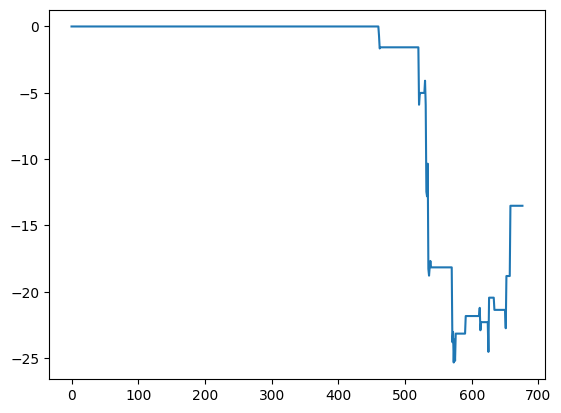

In [19]:
plt.plot(np.cumsum(report['percent_return_model']))

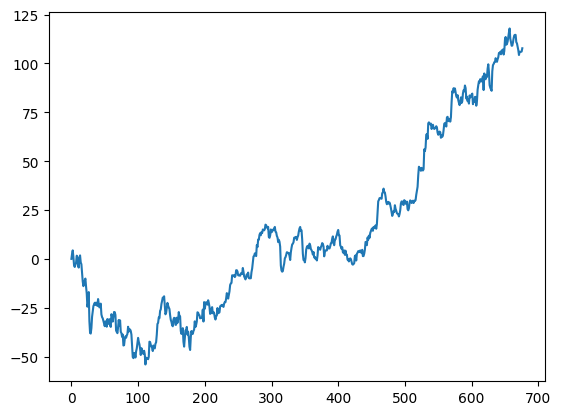

In [20]:
plt.plot(np.cumsum(report['percent_return']))

### Generating final model

In [21]:
if generate_last_model:
    data = process_data(start, end2)

    X = data.drop(columns=["Class", "Date"])
    y = data["Class"]

    if scaling:
        X = scaler.transform(X)
    else:
        X = X

    X = sel.transform(X)
    X = model.transform(X)

    xgboost = XGBClassifier(gs.best_params_, random_state=0)
    xgboost.fit(X, y)

### Structure files of pipeline

In [22]:
model_files(
    ticker_name=ticker,
    scaler=scaler,
    #model=[xgboost, sel, model],
    model=[xgboost, sel],
    model_type="serial_skl",
    tickers=tickers,
    indicators=real_indicators,
    drop="drop",
    binary=False,
    pca=None,
    plan=model_plan,
    version=model_version,
    report=report,
)

./models/basic/EMBR3.SA/v2.0/config.json created
./models/basic/EMBR3.SA/v2.0/scaler.pkl created
./models/basic/EMBR3.SA/v2.0/model.pkl created
./models/basic/EMBR3.SA/v2.0/variance.pkl created
./models/basic/EMBR3.SA/v2.0/report.json created
